# 02 · Training a simple CNN

Network: the CNN from the [PyTorch CIFAR10 tutorial](https://pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html), adapted to **1 input channel** (spectrogram 64 × 188) and 2 classes (`src/model/cnn.py`).

Training (`src/model/train.py`): Adam (lr 0.001), batch 16, 30 epochs, cross-entropy with class weights against the imbalance, fixed seed 42. After every epoch the model is evaluated on validation; the epoch with the best validation macro F1 is saved to `models/simple_cnn.pt`.

Metrics on train / val / test:
- **macro F1**: F1 of each class, averaged with equal weight;
- **FAR** (False Acceptance Ratio): women (class 0) accepted as class 1 / all class-0 samples;
- **FRR** (False Rejection Ratio): men (class 1) rejected as class 0 / all class-1 samples.

**Milestone 1 goal: macro F1 ≥ 0.6 on the training set.**

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")  # all paths are relative to the repo root
sys.path.insert(0, os.getcwd())
import subprocess
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
from src.model.cnn import SimpleCNN
model = SimpleCNN()
print(model)
print(f"trainable parameters: {sum(p.numel() for p in model.parameters()):,}")

SimpleCNN(
  (conv1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=9152, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=2, bias=True)
)
trainable parameters: 1,111,266


## Training

In [3]:
out = subprocess.run([sys.executable, "-m", "src.model.train"], capture_output=True, text=True)
print(out.stdout[-6000:], out.stderr[-2000:])

train:   55 clips, class counts [18 37]
val  :    8 clips, class counts [4 4]
test :   11 clips, class counts [5 6]
epoch   1  loss 0.7050  train F1 0.402  val F1 0.333  val FAR 1.000  val FRR 0.000
epoch   2  loss 0.6483  train F1 0.863  val F1 0.273  val FAR 1.000  val FRR 0.250
epoch   3  loss 0.5496  train F1 0.848  val F1 0.564  val FAR 0.000  val FRR 0.750
epoch   4  loss 0.4146  train F1 0.888  val F1 0.467  val FAR 0.750  val FRR 0.250
epoch   5  loss 0.3467  train F1 0.957  val F1 0.273  val FAR 1.000  val FRR 0.250
epoch   6  loss 0.2146  train F1 0.940  val F1 0.750  val FAR 0.250  val FRR 0.250
epoch   7  loss 0.2171  train F1 0.912  val F1 0.273  val FAR 1.000  val FRR 0.250
epoch   8  loss 0.1959  train F1 0.980  val F1 0.750  val FAR 0.250  val FRR 0.250
epoch   9  loss 0.1248  train F1 1.000  val F1 0.750  val FAR 0.250  val FRR 0.250
epoch  10  loss 0.0738  train F1 1.000  val F1 0.273  val FAR 1.000  val FRR 0.250
epoch  11  loss 0.0348  train F1 1.000  val F1 0.619  

## Learning curves

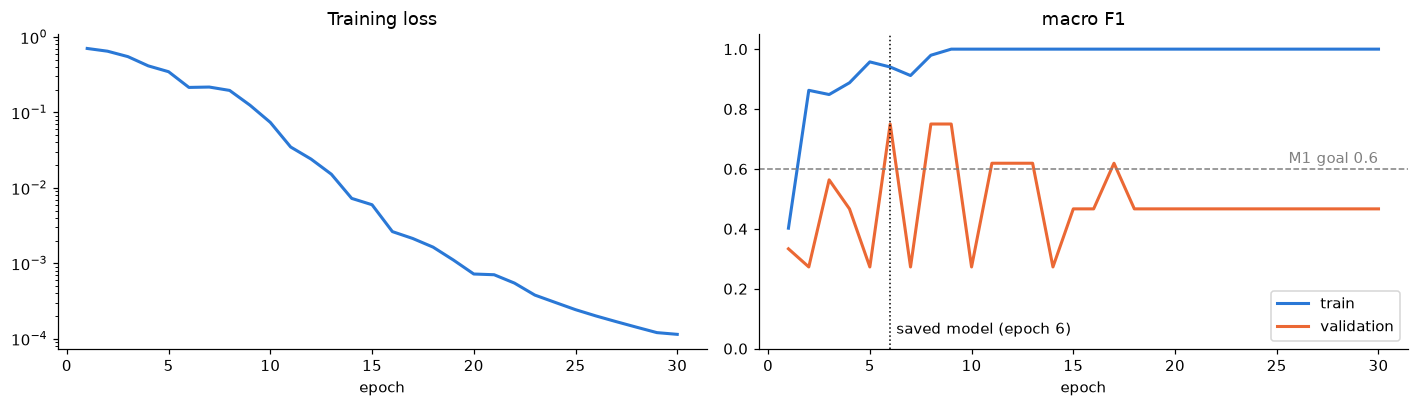

In [4]:
h = pd.read_csv("models/history.csv")
best = h.val_macro_f1.idxmax()
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(h.epoch, h.train_loss, color="#2a78d6", lw=2); ax[0].set_yscale("log")
ax[0].set_title("Training loss"); ax[0].set_xlabel("epoch")
ax[1].plot(h.epoch, h.train_macro_f1, color="#2a78d6", lw=2, label="train")
ax[1].plot(h.epoch, h.val_macro_f1, color="#eb6834", lw=2, label="validation")
ax[1].axhline(0.6, ls="--", c="gray", lw=1); ax[1].text(h.epoch.max(), 0.62, "M1 goal 0.6", ha="right", color="gray")
ax[1].axvline(h.epoch[best], ls=":", c="k", lw=1); ax[1].text(h.epoch[best] + .3, 0.05, f"saved model (epoch {h.epoch[best]})")
ax[1].set_ylim(0, 1.05); ax[1].set_title("macro F1"); ax[1].set_xlabel("epoch"); ax[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

Train F1 reaches 1.0 and the loss goes to ~0 while validation F1 stops improving: the network **overfits** (≈1.1 M parameters for 55 training clips). This is why we keep the model from the epoch with the best validation F1 (a simple form of early stopping) instead of the last one.

## Evaluation of the saved model

In [5]:
from torch.utils.data import DataLoader
from src.model.dataset import load_index, SpectrogramDataset
from src.model.split import get_split, PARTS
from src.model.metrics import compute_metrics
from src.model.train import predict

ckpt = torch.load("models/simple_cnn.pt")
model = SimpleCNN(input_shape=ckpt["input_shape"]); model.load_state_dict(ckpt["state_dict"])
idx = load_index(); split = get_split(idx)
preds = {p: predict(model, DataLoader(SpectrogramDataset(idx[idx.recording.isin(split[p])]), batch_size=64), "cpu") for p in PARTS}
res = pd.DataFrame({p: compute_metrics(*preds[p]) for p in PARTS}).T
res["clips"] = [len(preds[p][0]) for p in PARTS]
res.round(3)

,macro_f1,FAR,FRR,accuracy,clips
train,0.940,0.00,0.081,0.945,55
val,0.750,0.25,0.250,0.750,8
test,0.411,0.20,0.833,0.455,11


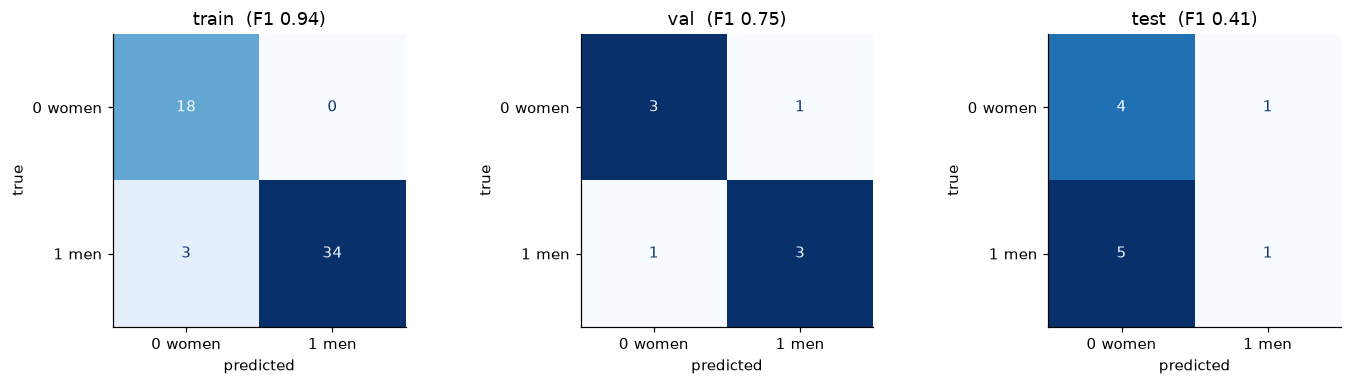

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a, p in zip(ax, PARTS):
    ConfusionMatrixDisplay(confusion_matrix(*preds[p], labels=[0, 1]), display_labels=["0 women", "1 men"]).plot(ax=a, colorbar=False, cmap="Blues")
    a.set_title(f"{p}  (F1 {res.loc[p, 'macro_f1']:.2f})"); a.set_xlabel("predicted"); a.set_ylabel("true")
plt.tight_layout(); plt.show()

In [7]:
print(f"Milestone 1 goal (macro F1 >= 0.6 on train): {'REACHED' if res.loc['train','macro_f1'] >= 0.6 else 'not reached'} "
      f"-> {res.loc['train','macro_f1']:.3f}")

Milestone 1 goal (macro F1 >= 0.6 on train): REACHED -> 0.940


## Conclusions and next steps

- The simple CNN learns the training data (goal reached), but generalizes poorly: validation and test are much worse than train.
- Validation and test are very small (8 and 11 clips), so a single clip changes FAR / FRR by 10–25 percentage points. The numbers are noisy.
- Milestone 2: more and longer recordings, split by speaker, data augmentation (noise, reverberation), dropout, batch normalization, a smaller fully connected part, different optimizers and learning-rate schedules.